# 03 — Softmax Regression trên MNIST

**Mục tiêu:** kiểm chứng gradient, khảo sát learning rate/L2, chọn cấu hình trên Validation, đối chiếu scikit-learn và phân tích kết quả Test.

Mô hình được cài đặt tại `src/models/softmax.py`, có các hàm `_grad()` và `_loss()`. `load_prepared_mnist()` phải trả về 6 mảng theo thứ tự Train, Validation, Test; ảnh đã chia 255 và trải phẳng, nhãn nguyên 0–9. Notebook giữ nguyên cách chia trong loader, không tự chia lại.

**Nguyên tắc:** không dùng Test để chọn cấu hình. Kết quả lưu vào `results/softmax/`; chạy lại ghi đè tệp cùng tên.


## 1. Thiết lập và nạp dữ liệu

**Mục tiêu:** dùng chung dữ liệu, seed và ngân sách huấn luyện trong các thí nghiệm. `BASE_L2 = 1/n_train` là mốc tham chiếu tương ứng C=1, không phải giá trị tối ưu mặc định.


In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
OUTPUT = ROOT / 'results' / 'softmax'
OUTPUT.mkdir(parents=True, exist_ok=True)
from src.data import load_prepared_mnist
from src.models.softmax import SoftmaxRegression
print('scikit-learn:', sklearn.__version__)
SEED = 42

X_all, y_all, X_test, y_test = load_prepared_mnist()
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=10000, stratify=y_all, random_state=SEED)
del X_all, y_all
print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)

EPOCHS, BATCH_SIZE = 100, 256
BASE_L2 = 1 / len(X_train)

scikit-learn: 1.9.1
Train: (50000, 784) (50000,)
Validation: (10000, 784) (10000,)
Test: (10000, 784) (10000,)


## 2. Hàm hỗ trợ thí nghiệm

Tính accuracy, precision/recall/F1 macro; chạy khảo sát và vẽ Validation CE. Mỗi cấu hình chạy đủ `EPOCHS` (`patience=None`), rồi khôi phục checkpoint được chấp nhận theo Validation CE với ngưỡng cải thiện 1e-6.

Chọn siêu tham số theo **Validation F1 macro**, CE thấp hơn dùng để phá hòa. CE được ghi không gồm L2; gradient huấn luyện vẫn có L2.


In [2]:
def metrics(y, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, pred, labels=np.arange(10), average='macro', zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision_macro=precision,
                recall_macro=recall, f1_macro=f1)

def experiment(values, parameter, learning_rate=0.1, l2=BASE_L2):
    models, rows = {}, []
    for value in values:
        params = dict(learning_rate=learning_rate, l2=l2)
        params[parameter] = value
        model = SoftmaxRegression(**params, epochs=EPOCHS, batch_size=BATCH_SIZE,
                                 random_state=SEED, patience=None, verbose=False)
        t0 = time.perf_counter()
        model.fit(X_train, y_train, X_val, y_val)
        seconds = time.perf_counter() - t0
        p = model.predict_proba(X_val)
        models[value] = model
        rows.append({parameter: value, **metrics(y_val, p.argmax(1)),
            'val_CE': model._loss(X_val, y_val),
            'train_accuracy': model.score(X_train, y_train),
            'weight_norm': np.linalg.norm(model.W_),
            'best_epoch': model.best_epoch_, 'n_iter': model.n_iter_, 'fit_seconds': seconds})
        print(f'{parameter}={value:g}: val F1={rows[-1]["f1_macro"]:.4f}', flush=True)
    return models, pd.DataFrame(rows)

def plot_experiment(models, parameter):
    fig, ax = plt.subplots(figsize=(8, 4))
    for value, model in models.items():
        loss = model.history_['val_loss']
        ax.plot(range(1, len(loss) + 1), loss, label=f'{parameter}={value:g}')
    ax.set(xlabel='Epoch', ylabel='Validation cross-entropy', title=f'Ảnh hưởng của {parameter}')
    ax.margins(x=0.05)
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT / f'survey_{parameter}.png', dpi=300)
    plt.show()

## 3. Kiểm chứng gradient

So sánh `_grad()` với sai phân hữu hạn của mục tiêu CE + L2 trên dữ liệu nhỏ ở float64. Kiểm tra cả W và b; các biến thử độc lập với mô hình MNIST. Kiểm tra này không thay thế đánh giá chất lượng dự đoán.


In [3]:
rng = np.random.default_rng(SEED)
Xc, yc = rng.normal(size=(8, 4)), np.arange(8)
m = SoftmaxRegression(l2=0.01, verbose=False)
m.W_ = rng.normal(0, 0.1, size=(4, 10))
m.b_ = rng.normal(0, 0.1, size=10)
dW, db = m._grad(Xc, yc)

def objective():
    return m._loss(Xc, yc) + 0.5 * m.l2 * np.sum(m.W_ ** 2)

step = 1e-5
gradient_rows = []
for name, param, grad in [('W', m.W_, dW), ('b', m.b_, db)]:
    numerical = np.zeros_like(param)
    for idx in np.ndindex(param.shape):
        old = param[idx]
        param[idx] = old + step; plus = objective()
        param[idx] = old - step; minus = objective()
        param[idx] = old
        numerical[idx] = (plus - minus) / (2 * step)
    passed = np.allclose(grad, numerical, atol=1e-7, rtol=1e-5)
    print(f'{name}: khớp={passed}, sai khác lớn nhất={np.max(np.abs(grad - numerical)):.2e}')
    gradient_rows.append(dict(parameter=name, max_absolute_error=float(np.max(np.abs(grad - numerical))), passed=bool(passed)))
    assert passed, f'Gradient {name} chưa khớp!'
pd.DataFrame(gradient_rows).to_csv(OUTPUT / 'gradient_check.csv', index=False)


W: khớp=True, sai khác lớn nhất=4.78e-11
b: khớp=True, sai khác lớn nhất=2.96e-11


## 4. Khảo sát siêu tham số

Khảo sát tuần tự: chọn learning rate tại L2 baseline, sau đó chọn L2 tại learning rate đã chọn. Đây không phải tìm kiếm toàn bộ tổ hợp hai tham số.


### 4.1. Learning rate

**Mục tiêu:** so sánh diễn biến CE và chất lượng checkpoint khi thay learning rate; giữ batch size, số epoch và L2 baseline cố định.


learning_rate=0.001: val F1=0.8742
learning_rate=0.01: val F1=0.9078
learning_rate=0.1: val F1=0.9202
learning_rate=0.5: val F1=0.9218
learning_rate=1: val F1=0.9216


,learning_rate,accuracy,precision_macro,recall_macro,f1_macro,val_CE,train_accuracy,weight_norm,best_epoch,n_iter,fit_seconds
0,0.001,0.8760,0.87565,0.87399,0.87418,0.49735,0.87684,4.391210,100,100,11.73129
1,0.010,0.9087,0.90816,0.90767,0.90775,0.32657,0.91256,8.472590,100,100,11.48202
2,0.100,0.9211,0.92025,0.92023,0.92016,0.28529,0.92950,14.866900,96,100,12.29700
3,0.500,0.9228,0.92196,0.92187,0.92180,0.28395,0.93330,20.224739,58,100,11.82054
4,1.000,0.9227,0.92197,0.92167,0.92165,0.28952,0.93432,24.833570,58,100,11.53683


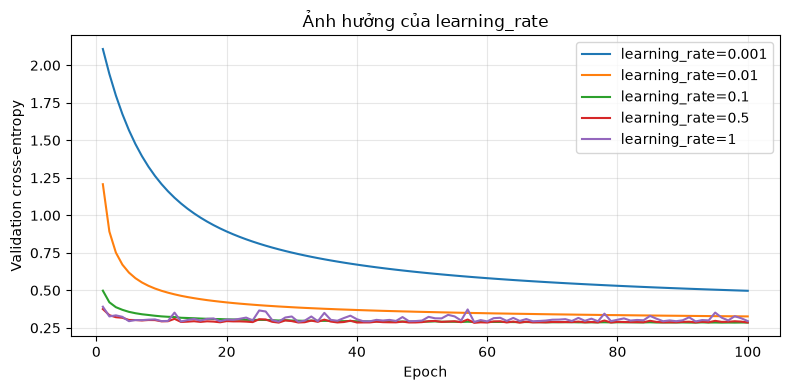

Learning rate được chọn: 0.5


In [4]:
LR_VALUES = [0.001, 0.01, 0.1, 0.5, 1.0]
lr_models, lr_results = experiment(LR_VALUES, 'learning_rate')
display(lr_results.round(5))
plot_experiment(lr_models, 'learning_rate')
best_lr_row = lr_results.sort_values(
    ['f1_macro', 'val_CE'], ascending=[False, True], kind='stable'
).iloc[0]
best_lr = float(best_lr_row['learning_rate'])
print('Learning rate được chọn:', best_lr)
lr_results.to_csv(OUTPUT / 'learning_rate.csv', index=False)

**Cách đọc:** xem CE giảm nhanh/chậm, mức dao động và F1 macro của checkpoint. Learning rate được chọn chỉ tốt nhất trong lưới tại L2 baseline. Viết nhận xét định lượng sau khi chạy; không suy ra kết quả từ tên siêu tham số.


### 4.2. L2 và lựa chọn cấu hình

**Mục tiêu:** đánh giá tác động regularization khi giữ learning rate đã chọn. Baseline được tái sử dụng, không fit lại. Điểm Train/Validation trong bảng được tính tại checkpoint đã khôi phục.


l2=0: val F1=0.9213
l2=0.0001: val F1=0.9216
l2=0.001: val F1=0.9161
l2=0.01: val F1=0.8958


,l2,accuracy,precision_macro,recall_macro,f1_macro,val_CE,train_accuracy,weight_norm,best_epoch,n_iter,fit_seconds
0,0.00000,0.9223,0.92142,0.92137,0.92129,0.28457,0.93392,20.963650,58,100,12.12772
4,0.00002,0.9228,0.92196,0.92187,0.92180,0.28395,0.93330,20.224739,58,100,11.82054
1,0.00010,0.9226,0.92181,0.92166,0.92162,0.28302,0.93234,17.846670,58,100,12.01628
2,0.00100,0.9171,0.91647,0.91608,0.91608,0.30113,0.92154,10.314260,58,100,11.54504
3,0.01000,0.8973,0.89712,0.89574,0.89575,0.40650,0.89782,5.459420,58,100,11.38880


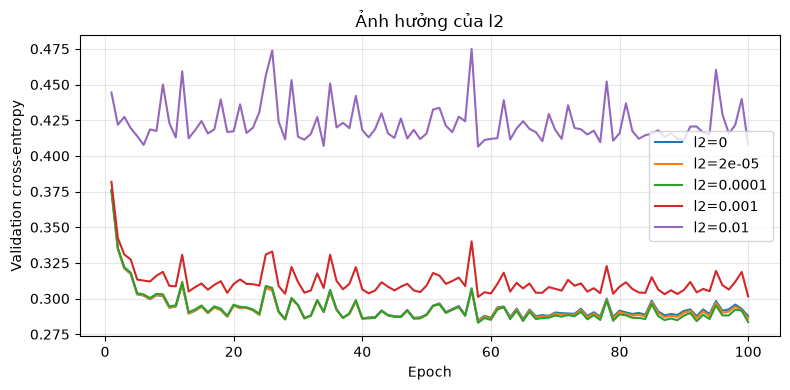

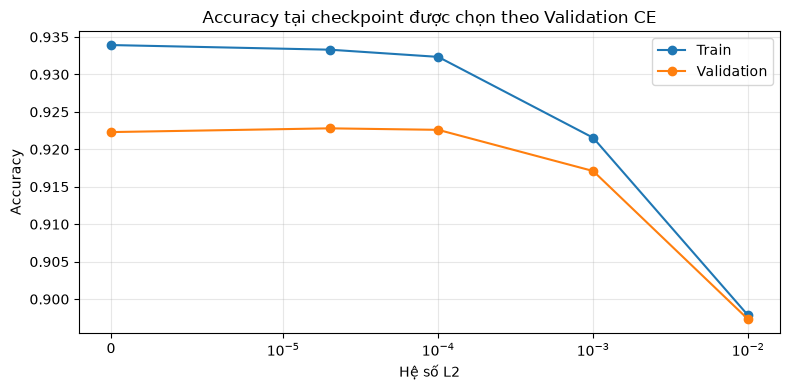

Cấu hình chọn: lr=0.5, L2=2e-05
Validation F1=0.9218, CE=0.2839
Checkpoint: epoch 58
Tổng thời gian fit khảo sát: 105.95s


In [5]:
L2_VALUES = [0, 1e-4, 1e-3, 1e-2]
l2_models, l2_results = experiment([v for v in L2_VALUES if v != BASE_L2], 'l2', learning_rate=best_lr)
l2_search_seconds = l2_results['fit_seconds'].sum()

l2_models[BASE_L2] = lr_models[best_lr]
baseline = lr_results.loc[lr_results['learning_rate'] == best_lr].drop(columns='learning_rate').copy()
baseline['l2'] = BASE_L2
l2_results = pd.concat([l2_results, baseline], ignore_index=True).sort_values('l2')

display(l2_results.round(5))
plot_experiment(dict(sorted(l2_models.items())), 'l2')

ax = l2_results.plot(x='l2', y=['train_accuracy', 'accuracy'], marker='o', figsize=(8, 4))
ax.set_xscale('symlog', linthresh=1e-5)
ax.margins(x=0.05)
ax.set(xlabel='Hệ số L2', ylabel='Accuracy', title='Accuracy tại checkpoint được chọn theo Validation CE')
ax.legend(['Train', 'Validation'])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT / 'l2_accuracy.png', dpi=300)
plt.show()

# Chọn F1 macro cao nhất -> CE thấp nhất.
best_row = l2_results.sort_values(['f1_macro', 'val_CE'], ascending=[False, True], kind='stable').iloc[0]
best_l2 = float(best_row['l2'])
manual = l2_models[best_l2]
manual_time = float(best_row['fit_seconds'])
search_seconds = lr_results['fit_seconds'].sum() + l2_search_seconds

# Lưu bảng và thông báo cấu hình.
l2_results.to_csv(OUTPUT / 'l2.csv', index=False)
print(f'Cấu hình chọn: lr={best_lr:g}, L2={best_l2:g}')
print(f'Validation F1={best_row["f1_macro"]:.4f}, CE={best_row["val_CE"]:.4f}')
print(f'Checkpoint: epoch {manual.best_epoch_}')
print(f'Tổng thời gian fit khảo sát: {search_seconds:.2f}s')

**Cách đọc:** so F1 macro, CE và chênh lệch accuracy Train–Validation. Mức phạt lớn không bảo đảm cải thiện chất lượng. Cấu hình đã chọn được giữ nguyên cho các bước sau, không điều chỉnh bằng Test.


## 5. Đường cong của cấu hình đã chọn

**Mục tiêu:** theo dõi CE và accuracy trên Train/Validation. Đường cong chứa toàn bộ epoch đã chạy, còn mô hình dùng trọng số tại checkpoint đánh dấu. CE không gồm L2. Tái sử dụng mô hình từ khảo sát, không fit lại.


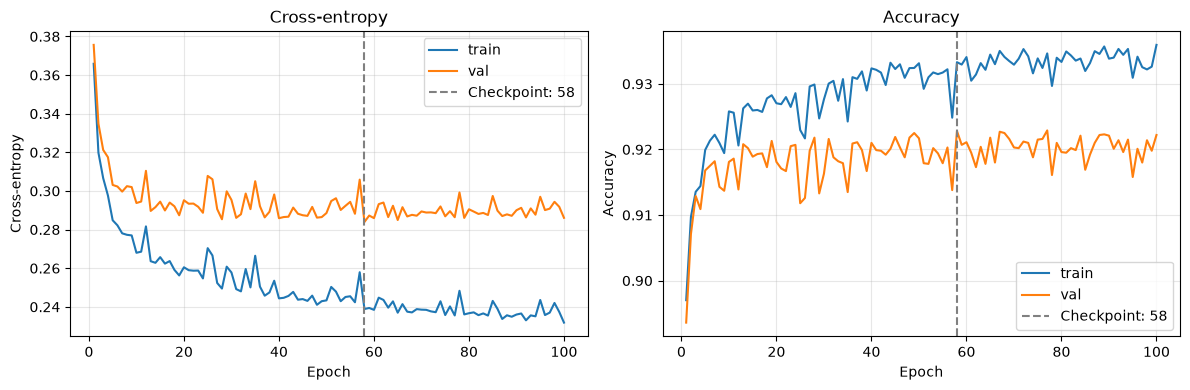

In [6]:
h = manual.history_
epochs = np.arange(1, len(h['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in ['train', 'val']:
    axes[0].plot(epochs, h[f'{split}_loss'], label=split)
    axes[1].plot(epochs, h[f'{split}_accuracy'], label=split)
for ax, title in zip(axes, ['Cross-entropy', 'Accuracy']):
    ax.axvline(manual.best_epoch_, color='gray', linestyle='--',
               label=f'Checkpoint: {manual.best_epoch_}')
    ax.set(xlabel='Epoch', ylabel=title, title=title)
    ax.margins(x=0.05)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT / 'training_curves.png', dpi=300)
plt.show()


**Nhận xét:** vạch dọc đánh dấu checkpoint được chọn theo CE, không nhất thiết trùng epoch có accuracy cao nhất.


## 6. Huấn luyện mô hình tham chiếu scikit-learn

Với mục tiêu mean CE + l2/2 × ||W||², quy đổi C = 1/(l2 × n_train). Nếu l2=0, dùng mô hình không phạt. Cả hai fit cùng Train; khác optimizer, dtype nội bộ và điều kiện dừng nên không yêu cầu kết quả trùng tuyệt đối.

Chỉ fit sklearn một lần. Giữ cảnh báo hội tụ nếu xuất hiện; số vòng lặp L-BFGS không tương đương số epoch SGD.


In [ ]:
C = 1 / (best_l2 * len(X_train)) if best_l2 > 0 else None
params = {'C': C} if C is not None else {'penalty': None}
reference = LogisticRegression(**params, solver='lbfgs', max_iter=300, tol=1e-4)
t0 = time.perf_counter()
reference.fit(X_train, y_train)
reference_time = time.perf_counter() - t0
print('Regularization:', params)
print(f'Thời gian fit: {reference_time:.2f}s; số vòng lặp: {reference.n_iter_}')


## 7. Đánh giá cuối và đối chiếu hai cài đặt

**Mục tiêu:** tổng hợp accuracy, precision/recall/F1 macro trên ba tập và vẽ confusion matrix của mô hình tự viết. Train là in-sample; Validation đã dùng chọn cấu hình; Test dùng đánh giá cuối.

`fit_seconds` là cùng một lần fit được lặp lại ở ba dòng, không cộng qua các split. Thời gian fit cấu hình tự viết đã nằm trong tổng fit khảo sát; không cộng trùng. Các thời gian đo một lần chỉ mang tính tham khảo.


,model,split,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,Softmax tự viết,Train,0.9333,0.9325,0.9323,0.9323,11.1506,0.0232
1,Softmax tự viết,Validation,0.9228,0.9220,0.9219,0.9218,11.1506,0.0036
2,Softmax tự viết,Test,0.9253,0.9244,0.9241,0.9241,11.1506,0.0089
3,Softmax sklearn,Train,0.9402,0.9395,0.9394,0.9394,431.2134,0.0452
4,Softmax sklearn,Validation,0.9217,0.9208,0.9207,0.9207,431.2134,0.0160
5,Softmax sklearn,Test,0.9241,0.9232,0.9230,0.9230,431.2134,0.0159


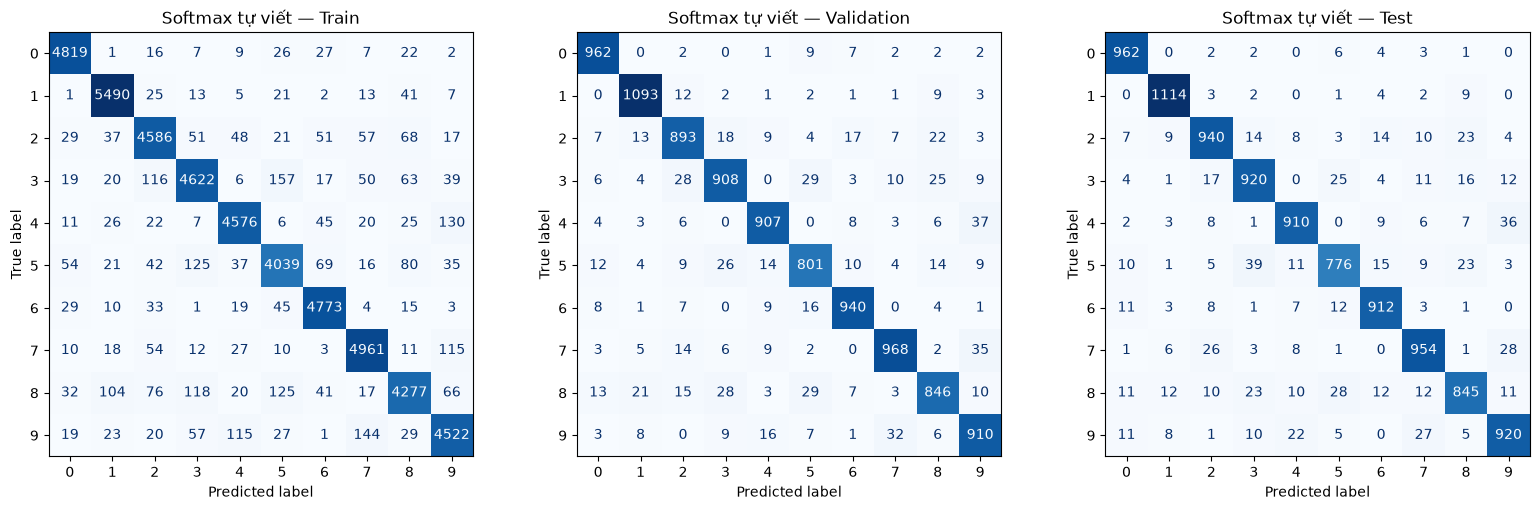

Test accuracy=92.53%; F1 macro=0.9241


In [ ]:
models = {'Softmax tự viết': manual, 'Softmax sklearn': reference}
datasets = {'Train': (X_train, y_train), 'Validation': (X_val, y_val), 'Test': (X_test, y_test)}
fit_times = {'Softmax tự viết': manual_time, 'Softmax sklearn': reference_time}

rows, predictions = [], {}
for name, model in models.items():
    for split, (X, y) in datasets.items():
        t0 = time.perf_counter()
        pred = model.predict(X)
        seconds = time.perf_counter() - t0
        predictions[name, split] = pred
        rows.append({
            'model': name, 'split': split, **metrics(y, pred),
            'fit_seconds': fit_times[name], 'predict_seconds': seconds
        })

results = pd.DataFrame(rows)
display(results.round(4))
results.to_csv(OUTPUT / 'metrics.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (split, (_, y)) in zip(axes, datasets.items()):
    ConfusionMatrixDisplay.from_predictions(
        y, predictions['Softmax tự viết', split], labels=np.arange(10),
        ax=ax, cmap='Blues', colorbar=False, values_format='d'
    )
    ax.set_title(f'Softmax tự viết — {split}')
    pd.DataFrame(confusion_matrix(y, predictions['Softmax tự viết', split], labels=np.arange(10)),
                 index=np.arange(10), columns=np.arange(10)).to_csv(
        OUTPUT / f'confusion_{split.lower()}.csv', index_label='true_digit')

fig.tight_layout()
fig.savefig(OUTPUT / 'confusion_matrices.png', dpi=300)
plt.show()

manual_test = results.query(
    "model == 'Softmax tự viết' and split == 'Test'"
).iloc[0]
print(f'Test accuracy={manual_test.accuracy:.2%}; F1 macro={manual_test.f1_macro:.4f}')

**Nhận xét:** train là in-sample, validation đã dùng để chọn cấu hình. Dùng test làm kết quả cuối; không kết luận overfitting chỉ từ một chênh lệch nhỏ giữa các tập.


## 8. Phân tích lỗi trên Test

**Mục tiêu:** đọc độ đo từng chữ số, ba hướng nhầm phổ biến nhất và tối đa 8 ảnh sai chọn ngẫu nhiên với seed cố định. Hướng 5 → 3 khác hướng 3 → 5. Các ảnh minh họa không chứng minh nguyên nhân của mọi lỗi.


,precision,recall,f1-score,support
0,0.9441,0.9816,0.9625,980.0000
1,0.9628,0.9815,0.9721,1135.0000
2,0.9216,0.9109,0.9162,1032.0000
3,0.9064,0.9109,0.9086,1010.0000
4,0.9324,0.9267,0.9295,982.0000
5,0.9055,0.8700,0.8874,892.0000
6,0.9363,0.9520,0.9441,958.0000
7,0.9200,0.9280,0.9240,1028.0000
8,0.9076,0.8676,0.8871,974.0000
9,0.9073,0.9118,0.9095,1009.0000


,Thật,Dự đoán,Số ảnh,Tỷ lệ trong lớp thật (%)
40,5,3,39,4.37
36,4,9,36,3.67
61,7,9,28,2.72


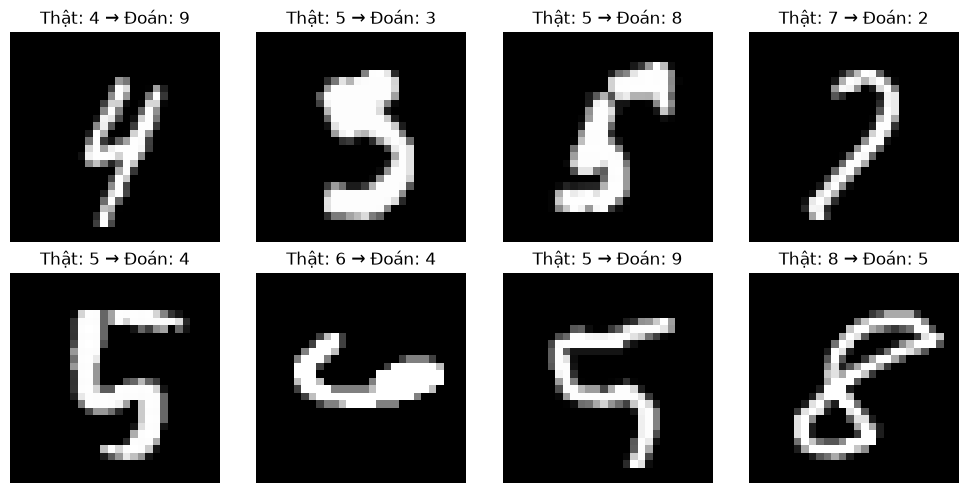

Số ảnh dự đoán sai: 747/10000


In [ ]:
pred = predictions['Softmax tự viết', 'Test']
report = pd.DataFrame(classification_report(
    y_test, pred, labels=np.arange(10), output_dict=True, zero_division=0
)).T
display(report.round(4))
report.to_csv(OUTPUT / 'classification_report_test.csv')
# Ba hướng nhầm phổ biến nhất: nhãn thật → nhãn dự đoán.
cm = confusion_matrix(y_test, pred, labels=np.arange(10))
pairs = [
    {'Thật': i, 'Dự đoán': j, 'Số ảnh': int(cm[i, j]),
     'Tỷ lệ trong lớp thật (%)': 100 * cm[i, j] / cm[i].sum()}
    for i in range(10) for j in range(10)
    if i != j and cm[i, j] > 0
]
top_errors = pd.DataFrame(pairs, columns=['Thật', 'Dự đoán', 'Số ảnh', 'Tỷ lệ trong lớp thật (%)']).sort_values(
    ['Số ảnh', 'Thật', 'Dự đoán'], ascending=[False, True, True]
).head(3)

display(top_errors.round(2))
top_errors.to_csv(OUTPUT / 'top3_errors_test.csv', index=False)
# Chọn ngẫu nhiên tối đa 8 ảnh sai với seed cố định.
wrong = np.flatnonzero(pred != y_test)
selected = np.random.default_rng(SEED).choice(
    wrong, size=min(8, len(wrong)), replace=False
)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, selected):
    ax.imshow(X_test[i].reshape(28, 28), cmap='gray')
    ax.set_title(f'Thật: {y_test[i]} → Đoán: {pred[i]}')

fig.tight_layout()
fig.savefig(OUTPUT / 'error_examples.png', dpi=300)
plt.show()
print(f'Số ảnh dự đoán sai: {len(wrong)}/{len(y_test)}')
pd.DataFrame(dict(test_index=selected, y_true=y_test[selected], y_pred=pred[selected])).to_csv(
    OUTPUT / 'error_example_indices.csv', index=False)


## 9. Trực quan trọng số

**Mục tiêu:** reshape từng cột W[:, k] thành ảnh 28×28 để quan sát tác động của pixel lên logit lớp k. Đỏ là trọng số dương, xanh là trọng số âm; cùng thang màu giữa các lớp. Đây là tham số chung của mô hình, không phải ảnh trung bình hay bản đồ xác suất. Muốn so hai lớp, xét hiệu trọng số của chúng.


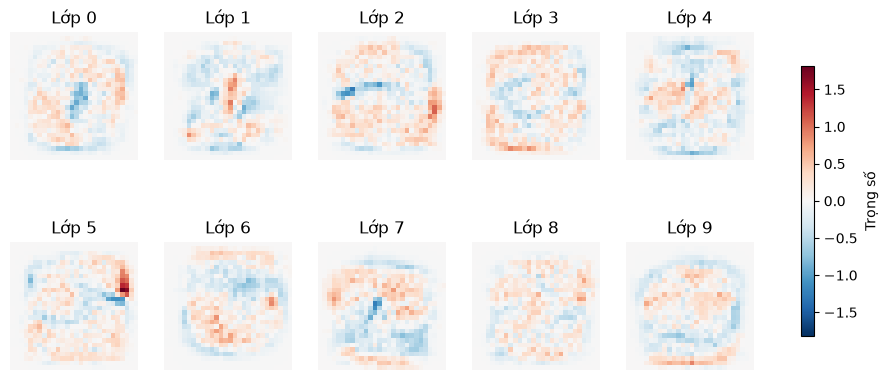

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
v = abs(manual.W_).max()
for k, ax in enumerate(axes.flat):
    im = ax.imshow(manual.W_[:, k].reshape(28, 28), cmap='RdBu_r', vmin=-v, vmax=v)
    ax.set_title(f'Lớp {manual.classes_[k]}'); ax.axis('off')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7, label='Trọng số')
fig.savefig(OUTPUT / 'weight_maps.png', dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét:** bảng theo lớp và ảnh sai hỗ trợ phân tích nhầm lẫn. Softmax chỉ học ranh giới tuyến tính trên pixel; so sánh với MLP/Ensemble cần cùng split và giao thức.


## 10. Lưu mô hình và cấu hình thực nghiệm

Các bảng và hình được lưu tại bước tạo ra chúng. Ô cuối lưu lịch sử CE/accuracy, trọng số và mô hình sklearn, dự đoán từng ảnh, lưới khảo sát, dtype và thời gian. Không huấn luyện thêm; chạy lại ghi đè tệp cùng tên. Seed và số mẫu chưa đủ chứng minh cùng chỉ số chia tập; chỉ số gốc cần được lưu từ loader nếu muốn kiểm tra điều này.


In [ ]:
import platform
import joblib

history = pd.DataFrame(manual.history_)
history.insert(0, 'epoch', np.arange(1, len(history) + 1))
history.to_csv(OUTPUT / 'history.csv', index=False)
np.savez_compressed(OUTPUT / 'manual_weights.npz', W=manual.W_, b=manual.b_, classes=manual.classes_)
joblib.dump(reference, OUTPUT / 'sklearn_model.joblib')
for name, tag in [('Softmax tự viết', 'manual'), ('Softmax sklearn', 'sklearn')]:
    for split, (_, y) in datasets.items():
        np.savez_compressed(OUTPUT / f'predictions_{tag}_{split.lower()}.npz',
                            y_true=y, y_pred=predictions[name, split])
config = dict(
    learning_rate=best_lr, l2=best_l2, epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED,
    baseline_l2=BASE_L2, learning_rate_grid=LR_VALUES, l2_grid=L2_VALUES,
    patience=None, best_epoch=int(manual.best_epoch_), n_iter=int(manual.n_iter_),
    dtype=str(X_train.dtype), weight_dtype=str(manual.W_.dtype),
    train_samples=len(y_train), validation_samples=len(y_val), test_samples=len(y_test),
    search_seconds=float(search_seconds), final_fit_seconds=float(manual_time),
    final_fit_included_in_search=True, sklearn_fit_seconds=float(reference_time),
    selection='Sequential search; validation F1 macro, CE breaks ties',
    checkpoint='Validation CE; improvement threshold 1e-6',
    sklearn_C=C, sklearn_params=reference.get_params(), sklearn_version=sklearn.__version__
)
(OUTPUT / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
environment = dict(python=sys.version, platform=platform.platform(), numpy=np.__version__,
                   pandas=pd.__version__, sklearn=sklearn.__version__, matplotlib=plt.matplotlib.__version__)
(OUTPUT / 'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print('Số tham số:', manual.W_.size + manual.b_.size)
print('Đã lưu:', OUTPUT)


Số tham số: 7850
Đã lưu: d:\Nhận dạng mẫu\mnist\results\softmax
